# Explore CIFAR-10 image embeddings

Load the vectors produced by [Prepare CIFAR-10 EmbeddingGemma 2 vectors](../data/prepare_cifar_dataset.ipynb), then compare recursive UMAP with IMSTE’s multilevel start and integrated gravity result. This notebook does not download CIFAR-10 or load the embedding model.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Could not locate this IMSTE repository from the notebook working directory.")
DATA_DIR = REPO_ROOT / "data" / "cifar10"
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Repository:", REPO_ROOT)
print("CIFAR-10 data:", DATA_DIR)


Repository: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree
CIFAR-10 data: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/cifar10


In [2]:
import hashlib
import json
import time

import numpy as np
import pandas as pd

MANIFEST_PATH = DATA_DIR / "cache" / "embeddinggemma2_cifar10_manifest.json"
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {MANIFEST_PATH}. Run ../data/prepare_cifar_dataset.ipynb first."
    )
manifest = json.loads(MANIFEST_PATH.read_text())
EMBEDDING_PATH = MANIFEST_PATH.parent / manifest["embedding_file"]
with np.load(EMBEDDING_PATH, allow_pickle=False) as saved:
    X = saved["embeddings"]
    labels = saved["labels"]
    sample_indices = saved["indices"]
class_names = manifest["class_names"]

if X.ndim != 2 or X.shape[1] != 768 or len(X) != len(labels):
    raise ValueError(f"Unexpected vector/label shapes: {X.shape}, {labels.shape}")
if not np.isfinite(X).all():
    raise ValueError("The saved image vectors contain NaN or infinite values.")
actual_fingerprint = hashlib.sha256(np.ascontiguousarray(X).view(np.uint8)).hexdigest()
if actual_fingerprint != manifest["vector_sha256"]:
    raise ValueError("The saved vectors do not match the manifest fingerprint.")

print("Dataset:", manifest["dataset"])
print("Encoder:", manifest["model_id"])
print("Vector matrix:", X.shape, X.dtype)
print("Loaded from:", EMBEDDING_PATH)


Dataset: CIFAR-10 train
Encoder: google/embeddinggemma-2
Vector matrix: (1000, 768) float32
Loaded from: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/cifar10/cache/cifar10_train_100_per_class_seed42_embeddinggemma_2.npz


## 1. Fit recursive UMAP and IMSTE

Both layouts use the same normalized image vectors. CIFAR-10 labels are reserved for coloring the final plots.

In [3]:
import hashlib
import json
import time

FORCE_REFIT_UMAP = False
FORCE_REFIT_IMSTE = False


In [4]:
import umap

UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "init": "recursive",
    "recursive_coarsening_ratio": 4,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": int(manifest["random_state"]),
    "n_epochs": 200,
    "repulsion_strength": 1.0,
    "verbose": True,
}

def cache_key(payload):
    canonical = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(canonical).hexdigest()[:16]

umap_cache = CACHE_DIR / f"cifar10_umap_{cache_key({'vectors': manifest['vector_sha256'], 'settings': UMAP_SETTINGS})}.npz"
if umap_cache.is_file() and not FORCE_REFIT_UMAP:
    with np.load(umap_cache, allow_pickle=False) as saved:
        Z_umap = saved["embedding"]
        umap_seconds = float(saved["seconds"])
    print("Loaded cached UMAP layout:", umap_cache.name)
else:
    umap_started = time.perf_counter()
    Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
    umap_seconds = time.perf_counter() - umap_started
    np.savez_compressed(umap_cache, embedding=Z_umap, seconds=umap_seconds)
    print(f"UMAP fit in {umap_seconds / 60:.1f} min")
print("UMAP coordinates:", Z_umap.shape)


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, verbose=True)
Thu Nov 12 22:33:20 2026 Construct fuzzy simplicial set
Thu Nov 12 22:33:21 2026 Finding Nearest Neighbors
Thu Nov 12 22:33:30 2026 Finished Nearest Neighbor Search
Thu Nov 12 22:33:44 2026 Construct embedding
Thu Nov 12 22:33:44 2026 Using adam layout optimizer


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Epochs completed:   0%|            0/200 [00:00]

Thu Nov 12 22:33:45 2026 Finished embedding
UMAP fit in 0.4 min
UMAP coordinates: (1000, 2)


In [5]:
from imste import IteratedMinimumSpanningTreeEmbedder

IMSTE_SETTINGS = {
    "n_components": 2,
    "n_msts": 4,
    "n_epochs": 500,
    "batch_size": 32_768,
    "learning_rate": 0.05,
    "negative_ratio": 1,
    "lambda_rep": 0.5,
    "random_state": int(manifest["random_state"]),
    "mst_method": "famst",
    "mst_neighbor_backend": "auto",
    "multilevel_init": True,
    "multilevel_reduction_ratio": 4,
    "multilevel_base_size": 1_024,
    "multilevel_epochs": 10,
    "gravity_mode": "mexican_hat",
    "gravity_neighbors": 15,
    "gravity_resolution": 0.8,
    "gravity_strength": 0.3,
    "gravity_mass_power": 1.0,
    "gravity_attraction_strength": 0.5,
    "gravity_near_repulsion_strength": 1.5,
    "gravity_force_neighbors": 8,
    "gravity_attraction_range": 1.0,
    "gravity_repulsion_range": 0.2,
    "gravity_step_size": 0.05,
    "gravity_iterations": 3,
    "device": "auto",
    "verbose": True,
}

imste_cache = CACHE_DIR / f"cifar10_imste_{cache_key({'vectors': manifest['vector_sha256'], 'settings': IMSTE_SETTINGS})}.npz"
if imste_cache.is_file() and not FORCE_REFIT_IMSTE:
    with np.load(imste_cache, allow_pickle=False) as saved:
        Z_imste_base = saved["base"]
        Z_imste = saved["gravity"]
        imste_seconds = float(saved["imste_seconds"])
        gravity_seconds = float(saved["gravity_seconds"])
    print("Loaded cached IMSTE layouts:", imste_cache.name)
else:
    imste_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_SETTINGS)
    Z_imste_base, Z_imste = imste_estimator.fit_transform(X, return_intermediate=True)
    imste_seconds = imste_estimator.imste_fit_time_
    gravity_seconds = imste_estimator.gravity_time_
    np.savez_compressed(
        imste_cache,
        base=Z_imste_base,
        gravity=Z_imste,
        imste_seconds=imste_seconds,
        gravity_seconds=gravity_seconds,
    )
    print("Saved IMSTE layouts:", imste_cache.name)
print(f"IMSTE fit {imste_seconds:.1f}s; gravity {gravity_seconds:.1f}s")


Thu Nov 12 22:34:07 2026 IteratedMinimumSpanningTreeEmbedder({'batch_size': 32768, 'device': 'auto', 'epsilon': 0.0001, 'gravity_attraction_range': 1.0, 'gravity_attraction_strength': 0.5, 'gravity_core_quantile': 0.95, 'gravity_force_neighbors': 8, 'gravity_iterations': 3, 'gravity_mass_power': 1.0, 'gravity_mode': 'mexican_hat', 'gravity_near_repulsion_strength': 1.5, 'gravity_neighbors': 15, 'gravity_repulsion_range': 0.2, 'gravity_resolution': 0.8, 'gravity_step_size': 0.05, 'gravity_strength': 0.3, 'include_knn_attraction': False, 'lambda_rep': 0.5, 'learning_rate': 0.05, 'logistic_margin': 1.0, 'logistic_temperature': 0.5, 'metric': 'euclidean', 'mst_inter_component_edges': 5, 'mst_max_neighbors': None, 'mst_method': 'famst', 'mst_neighbor_backend': 'auto', 'mst_neighbors': 15, 'mst_representatives_per_component': 10, 'multilevel_base_size': 1024, 'multilevel_epochs': 10, 'multilevel_init': True, 'multilevel_reduction_ratio': 4, 'n_components': 2, 'n_epochs': 500, 'n_msts': 4, 'n

Construct MST graph:   0%|          | 0/4 [00:00<?, ?steps/s]

Building RP forest with 7 trees...
Initializing graph from 156 leaves...
Running NN-descent for up to 10 iterations...
Iteration 1: 1358 updates
Iteration 2: 132 updates
Iteration 3: 8 updates
Converged after 3 iterations

=== Timing Breakdown ===
Forest building:      53.259ms
Leaf initialization:  46.496ms
Candidate building:   12.778ms (3 iters)
Update iterations:    61.228ms (3 iters)
Total measured:      173.760ms
Thu Nov 12 22:34:07 2026 MST graph construction complete: 0.738s
Thu Nov 12 22:34:07 2026 Multilevel initialization complete: 0.008s
Thu Nov 12 22:34:08 2026 Final embedding optimization


Final embedding epochs:   0%|          | 0/500 [00:00<?, ?epoch/s]

Thu Nov 12 22:34:13 2026 Final embedding optimization complete: 5.344s
Thu Nov 12 22:34:31 2026 Finished embedding
Thu Nov 12 22:34:31 2026 === Timing Breakdown ===
Thu Nov 12 22:34:31 2026 MST graph construction: 0.738s
Thu Nov 12 22:34:31 2026 Multilevel initialization: 0.008s
Thu Nov 12 22:34:31 2026 Final embedding optimization: 5.344s
Thu Nov 12 22:34:31 2026 Embedding optimization: 5.856s
Thu Nov 12 22:34:31 2026   Negative sampling: 1.944s
Thu Nov 12 22:34:31 2026   Coordinate updates: 1.999s
Thu Nov 12 22:34:31 2026 Total measured: 24.149s
Thu Nov 12 22:34:31 2026 Multilevel initialization is included in embedding optimization.
Saved IMSTE layouts: cifar10_imste_25560d151503bb66.npz
IMSTE fit 6.6s; gravity 17.4s


## 2. View the embeddings

Each point is one image. Color indicates its CIFAR-10 class.

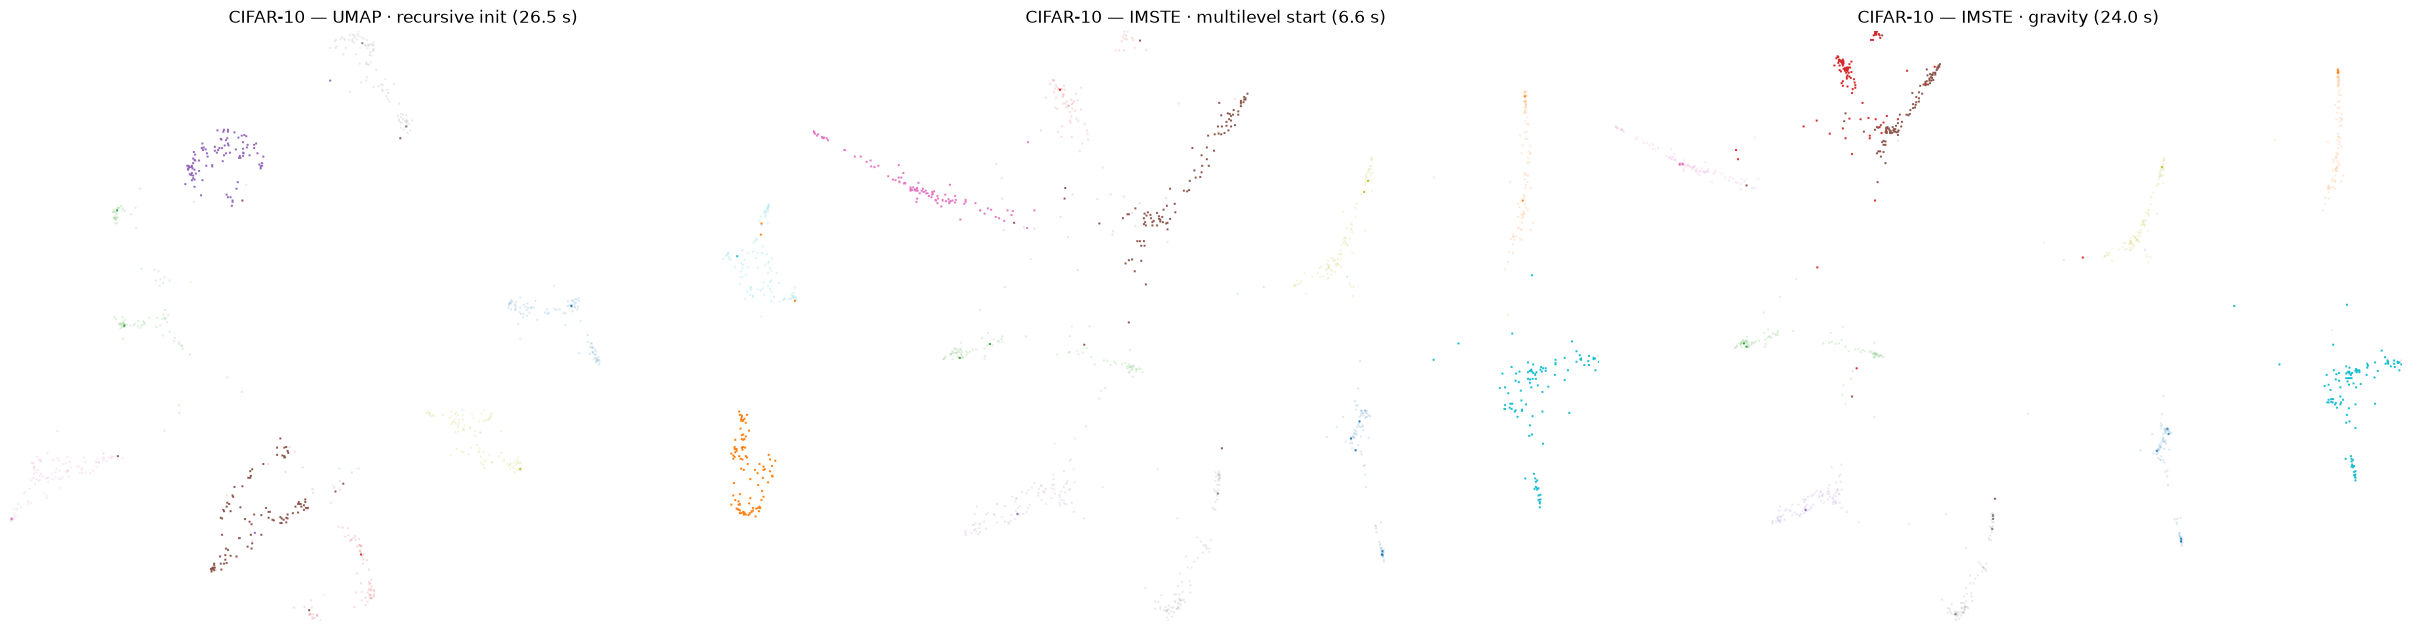

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from imste.visualization import render_datashader_embedding

labels_for_plot = np.asarray([class_names[int(label)] for label in labels])
palette = plt.get_cmap("tab10")
color_key = {name: to_hex(palette(i)) for i, name in enumerate(class_names)}
layouts = [
    ("UMAP · recursive init", Z_umap, umap_seconds),
    ("IMSTE · multilevel start", Z_imste_base, imste_seconds),
    ("IMSTE · gravity", Z_imste, imste_seconds + gravity_seconds),
]
fig, axes = plt.subplots(1, len(layouts), figsize=(8 * len(layouts), 7), constrained_layout=True)
for ax, (name, coordinates, elapsed) in zip(axes, layouts):
    image = render_datashader_embedding(
        coordinates,
        labels_for_plot,
        width=1200,
        height=900,
        color_key=color_key,
        min_alpha=40,
        background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{elapsed / 60:.1f} min" if elapsed >= 60 else f"{elapsed:.1f} s"
    ax.set_title(f"CIFAR-10 — {name} ({runtime})")
    ax.set_axis_off()
plt.show()
